# 07 — Prédiction

**Objectif** : appliquer le modèle retenu au mois le plus récent et écrire
`outputs/predictions/predictions.csv`.

On prédit le mois **suivant** à partir des variables du dernier mois observé.

In [1]:
import importlib
import sys
from pathlib import Path

racine = Path.cwd().resolve()
if not (racine / "src").is_dir():
    racine = racine.parent
sys.path.insert(0, str(racine))

import src

importlib.reload(src)


import joblib
import matplotlib.pyplot as plt
import pandas as pd

from src import FEATURES_CSV, FIGURES_DIR, MODELS_DIR, PREDICTIONS_DIR

In [2]:
artefact = joblib.load(MODELS_DIR / "best_model.pkl")
modele = artefact["modele"]
EXPLICATIVES = artefact["explicatives"]

print(f"Modèle : {artefact['nom']}")
print(f"MAE sur la période de test : {artefact['metriques_test']['mae']:.1f} ventes")

Modèle : Forêt aléatoire
MAE sur la période de test : 40.5 ventes


In [3]:
features = pd.read_csv(FEATURES_CSV, parse_dates=["periode"])
manquantes = [c for c in EXPLICATIVES if c not in features.columns]
assert not manquantes, f"Variables absentes : {manquantes}"

derniere = features["periode"].max()
a_predire = features[features["periode"] == derniere].copy()
print(f"Mois d'entrée : {derniere:%Y-%m} ({len(a_predire)} séries région × plage)")

Mois d'entrée : 2026-07 (48 séries région × plage)


In [4]:
a_predire["ventes_prevues"] = modele.predict(a_predire[EXPLICATIVES])
a_predire["ventes_prevues"] = a_predire["ventes_prevues"].clip(lower=0).round()

marge = artefact["metriques_test"]["mae"]
a_predire["borne_basse"] = (a_predire["ventes_prevues"] - marge).clip(lower=0).round()
a_predire["borne_haute"] = (a_predire["ventes_prevues"] + marge).round()

predictions = a_predire[
    [
        "periode",
        "id_region",
        "region",
        "plage_prix",
        "ventes_retard_1",
        "ventes_prevues",
        "borne_basse",
        "borne_haute",
    ]
].rename(columns={"periode": "periode_reference", "ventes_retard_1": "ventes_mois_precedent"})

predictions["periode_predite"] = predictions["periode_reference"] + pd.DateOffset(months=1)
predictions.sort_values(["region", "plage_prix"])

,periode_reference,id_region,region,plage_prix,ventes_mois_precedent,ventes_prevues,borne_basse,borne_haute,periode_predite
1264,2026-07-01,8,Abitibi-Témiscamingue,De 250 000 $ à 500 000 $,187.0,139.0,99.0,179.0,2026-08-01
1209,2026-07-01,8,Abitibi-Témiscamingue,Moins de 250 000 $,183.0,145.0,105.0,185.0,2026-08-01
1319,2026-07-01,8,Abitibi-Témiscamingue,Plus de 500 000 $,45.0,43.0,3.0,83.0,2026-08-01
109,2026-07-01,1,Bas-Saint-Laurent,De 250 000 $ à 500 000 $,247.0,171.0,131.0,211.0,2026-08-01
54,2026-07-01,1,Bas-Saint-Laurent,Moins de 250 000 $,317.0,227.0,187.0,267.0,2026-08-01
164,2026-07-01,1,Bas-Saint-Laurent,Plus de 500 000 $,63.0,42.0,2.0,82.0,2026-08-01
439,2026-07-01,3,Capitale-Nationale,De 250 000 $ à 500 000 $,1369.0,655.0,615.0,695.0,2026-08-01
384,2026-07-01,3,Capitale-Nationale,Moins de 250 000 $,364.0,304.0,264.0,344.0,2026-08-01
494,2026-07-01,3,Capitale-Nationale,Plus de 500 000 $,865.0,443.0,403.0,483.0,2026-08-01
2582,2026-07-01,17,Centre-du-Québec,De 250 000 $ à 500 000 $,394.0,253.0,213.0,293.0,2026-08-01


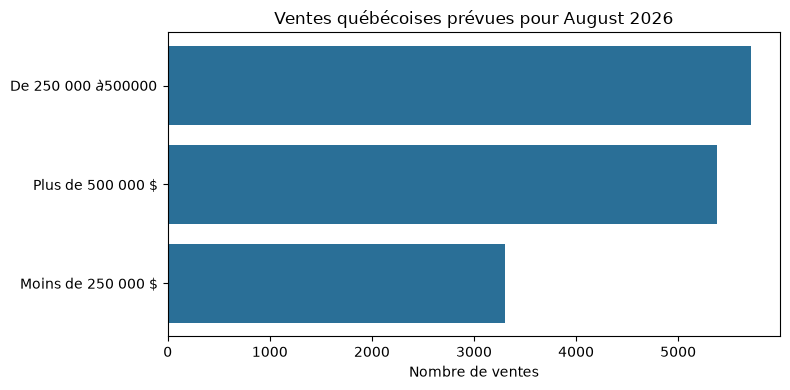

Total prévu : 14,390 ventes


In [5]:
par_plage = (
    predictions.groupby("plage_prix", as_index=False)["ventes_prevues"]
    .sum()
    .sort_values("ventes_prevues")
)

plt.figure(figsize=(8, 4))
plt.barh(par_plage["plage_prix"], par_plage["ventes_prevues"], color="#2a6f97")
plt.title(f"Ventes québécoises prévues pour {predictions['periode_predite'].iloc[0]:%B %Y}")
plt.xlabel("Nombre de ventes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Total prévu : {predictions['ventes_prevues'].sum():,.0f} ventes")

In [6]:
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
destination = PREDICTIONS_DIR / "predictions.csv"
predictions.to_csv(destination, index=False, encoding="utf-8")
print(f"Écrit : {destination}")

Écrit : C:\Users\Claude1\Documents\Projet d'analyse\Projet-marche-immobilier-quebec\outputs\predictions\predictions.csv


## Limites

- Horizon d'un mois seulement : au-delà, les retards devraient être alimentés
  par les prévisions, ce qui cumule l'erreur.
- Aucune variable exogène (taux d'intérêt, mises en chantier, migration).
- Les bornes reposent sur le MAE de test, pas sur un intervalle calibré.
- Le fichier mélange tous les types de propriétés.